# Mauritanian Languages — Data Quality & EDA Report

Notebook version of `generate_eda_pdf_report.py`. Run all cells top to bottom; the build cell writes the PDF to `data/processed/reports/Mauritanian_Languages_EDA_Report.pdf` and the last cells preview the EDA tables and charts inline.

**Requires:** `pandas matplotlib seaborn reportlab`

## 0. Install dependencies
Run this cell first. If you see a `ModuleNotFoundError` afterwards, restart the kernel (Kernel → Restart) and run all cells again.

In [1]:
# Run once. Installs into the SAME Python that runs this notebook.
%pip install -q pandas matplotlib seaborn reportlab pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from __future__ import annotations

import argparse
import re
import sys
import tempfile
import unicodedata
from collections import Counter
from datetime import datetime
from pathlib import Path
from xml.sax.saxutils import escape

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
from reportlab.platypus import (BaseDocTemplate, Frame, Image, KeepTogether,
                                PageBreak, PageTemplate, Paragraph, Spacer,
                                Table, TableStyle)

## Constants

In [3]:
# --------------------------------------------------------------------------
# Constants
# --------------------------------------------------------------------------
NAVY = colors.HexColor("#12284C")
TEAL = colors.HexColor("#0E8A8A")
LIGHT = colors.HexColor("#EAF4F4")
GRID = colors.HexColor("#B8C4CE")

LANG_NAMES = {"mey": "Hassaniya", "fuc": "Pulaar", "snk": "Soninke", "wol": "Wolof"}
LANG_ORDER = ["mey", "fuc", "snk", "wol"]
LEVEL_ORDER = ["word", "phrase", "sentence", "paragraph"]
TRANSLATION_COLS = ["text_arabic", "text_french", "text_english"]

# Pipeline figures supplied in the project brief (used when files can't confirm)
RAW_TOTAL, CLEAN_TOTAL, QUARANTINE_N = 10080, 9612, 17
MERGED_ROWS, CONFLICTS_N, NEAR_DUP_N = 451, 386, 103

## Path resolution & IO

In [4]:
# --------------------------------------------------------------------------
# Path resolution & IO
# --------------------------------------------------------------------------
def find_project_root(explicit: str | None = None) -> Path:
    """Locate the folder that contains data/processed/."""
    if explicit:
        p = Path(explicit).resolve()
        if (p / "data" / "processed").is_dir():
            return p
        sys.exit(f"[error] {p} does not contain data/processed/")
    starts = [Path.cwd().resolve(), Path(globals().get("__file__", ".")).resolve().parent]
    for start in starts:
        for cand in [start, *start.parents]:
            if (cand / "data" / "processed").is_dir():
                return cand
        # also look one level down (e.g. run from parent of the project)
        for child in start.iterdir() if start.is_dir() else []:
            if child.is_dir() and (child / "data" / "processed").is_dir():
                return child
    sys.exit("[error] Could not find a project root containing data/processed/. "
             "Use --root /path/to/mauritanian-langs")


def read_csv(path: Path) -> pd.DataFrame | None:
    if not path.exists():
        print(f"[warn] missing: {path}")
        return None
    try:
        return pd.read_csv(path, encoding="utf-8-sig", dtype=str,
                           keep_default_na=False, na_values=[""])
    except Exception as exc:  # noqa: BLE001
        print(f"[warn] could not read {path}: {exc}")
        return None


def first_col(df: pd.DataFrame | None, candidates: list[str]) -> str | None:
    if df is None:
        return None
    lower = {c.lower(): c for c in df.columns}
    for c in candidates:
        if c.lower() in lower:
            return lower[c.lower()]
    return None

## Fonts & styles

In [5]:
# --------------------------------------------------------------------------
# Fonts & styles
# --------------------------------------------------------------------------
def register_fonts() -> tuple[str, str]:
    """Register DejaVu (bundled with matplotlib) for broad Unicode coverage."""
    try:
        base = Path(matplotlib.get_data_path()) / "fonts" / "ttf"
        pdfmetrics.registerFont(TTFont("DejaVu", str(base / "DejaVuSans.ttf")))
        pdfmetrics.registerFont(TTFont("DejaVu-Bold", str(base / "DejaVuSans-Bold.ttf")))
        pdfmetrics.registerFontFamily("DejaVu", normal="DejaVu", bold="DejaVu-Bold")
        return "DejaVu", "DejaVu-Bold"
    except Exception as exc:  # noqa: BLE001
        print(f"[warn] DejaVu unavailable ({exc}); using Helvetica")
        return "Helvetica", "Helvetica-Bold"


def build_styles(font: str, bold: str) -> dict[str, ParagraphStyle]:
    ss = getSampleStyleSheet()
    return {
        "title": ParagraphStyle("title", parent=ss["Title"], fontName=bold, fontSize=26,
                                textColor=NAVY, alignment=TA_CENTER, leading=32),
        "subtitle": ParagraphStyle("subtitle", parent=ss["Normal"], fontName=font, fontSize=13,
                                   textColor=TEAL, alignment=TA_CENTER, leading=18),
        "h1": ParagraphStyle("h1", parent=ss["Heading1"], fontName=bold, fontSize=16,
                             textColor=NAVY, spaceBefore=6, spaceAfter=8),
        "h2": ParagraphStyle("h2", parent=ss["Heading2"], fontName=bold, fontSize=12,
                             textColor=TEAL, spaceBefore=10, spaceAfter=4),
        "body": ParagraphStyle("body", parent=ss["BodyText"], fontName=font, fontSize=9.5,
                               leading=14, spaceAfter=6),
        "bullet": ParagraphStyle("bullet", parent=ss["BodyText"], fontName=font, fontSize=9.5,
                                 leading=13.5, leftIndent=14, bulletIndent=4, spaceAfter=3),
        "cell": ParagraphStyle("cell", parent=ss["BodyText"], fontName=font, fontSize=7.5,
                               leading=9.5),
        "cellh": ParagraphStyle("cellh", parent=ss["BodyText"], fontName=bold, fontSize=7.5,
                                leading=9.5, textColor=colors.white),
        "caption": ParagraphStyle("caption", parent=ss["Italic"], fontName=font, fontSize=8,
                                  textColor=colors.HexColor("#555555"), alignment=TA_CENTER,
                                  spaceAfter=10),
        "code": ParagraphStyle("code", parent=ss["Code"], fontName="Courier", fontSize=7.5,
                               leading=10, backColor=LIGHT, borderPadding=4, spaceAfter=8),
    }

## PDF building blocks

In [6]:
# --------------------------------------------------------------------------
# PDF building blocks
# --------------------------------------------------------------------------
def P(text: str, style: ParagraphStyle) -> Paragraph:
    return Paragraph(text, style)


def safe(val, maxlen: int = 90) -> str:
    """Escape + truncate arbitrary cell content; make invisible chars visible."""
    if val is None or (isinstance(val, float) and pd.isna(val)):
        return "<i>(null)</i>"
    s = str(val)
    if s == "":
        return "<i>(empty)</i>"
    s = s.replace("\n", "\\n").replace("\r", "\\r").replace("\t", "\\t")
    if len(s) > maxlen:
        s = s[: maxlen - 1] + "…"
    return escape(s)


def make_table(df: pd.DataFrame, st: dict, col_widths: list[float] | None = None,
               total_width: float = 17 * cm, max_cell: int = 90) -> Table:
    """Render a DataFrame as a styled native PDF table (wrapped cells)."""
    header = [P(escape(str(c)), st["cellh"]) for c in df.columns]
    rows = [[P(safe(v, max_cell), st["cell"]) for v in r] for r in df.itertuples(index=False)]
    if col_widths is None:
        col_widths = [total_width / len(df.columns)] * len(df.columns)
    t = Table([header, *rows], colWidths=col_widths, repeatRows=1)
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), NAVY),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, LIGHT]),
        ("GRID", (0, 0), (-1, -1), 0.4, GRID),
        ("LINEBELOW", (0, 0), (-1, 0), 1.2, TEAL),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 4), ("RIGHTPADDING", (0, 0), (-1, -1), 4),
        ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3),
    ]))
    return t


def fig_image(path: Path, width: float = 16.5 * cm) -> Image:
    from PIL import Image as PILImage  # installed with matplotlib
    with PILImage.open(path) as im:
        w, h = im.size
    return Image(str(path), width=width, height=width * h / w)


def bullets(items: list[str], st: dict) -> list:
    return [Paragraph(t, st["bullet"], bulletText="•") for t in items]


class ReportDoc(BaseDocTemplate):
    """Document with header band, footer and page numbers."""

    def __init__(self, filename: str, font: str, **kw):
        super().__init__(filename, pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm,
                         topMargin=2.2 * cm, bottomMargin=1.8 * cm,
                         title="Mauritanian Languages - Data Quality & EDA Report",
                         author="Data Engineering", **kw)
        self.font = font
        frame = Frame(self.leftMargin, self.bottomMargin, self.width, self.height, id="f")
        self.addPageTemplates([PageTemplate(id="main", frames=[frame], onPage=self._decorate)])

    def _decorate(self, canv, doc):
        w, h = A4
        canv.saveState()
        canv.setFillColor(NAVY)
        canv.rect(0, h - 1.3 * cm, w, 1.3 * cm, stroke=0, fill=1)
        canv.setFillColor(TEAL)
        canv.rect(0, h - 1.45 * cm, w, 0.15 * cm, stroke=0, fill=1)
        canv.setFillColor(colors.white)
        canv.setFont(self.font, 9)
        canv.drawString(2 * cm, h - 0.85 * cm, "mauritanian-langs  |  Data Quality & EDA Report")
        canv.setFillColor(colors.HexColor("#666666"))
        canv.setFont(self.font, 8)
        canv.drawString(2 * cm, 1.0 * cm, f"Generated {datetime.now():%Y-%m-%d %H:%M}")
        canv.drawRightString(w - 2 * cm, 1.0 * cm, f"Page {doc.page}")
        canv.restoreState()

## Analysis helpers

In [7]:
# --------------------------------------------------------------------------
# Analysis helpers
# --------------------------------------------------------------------------
def find_flag_column(q: pd.DataFrame | None) -> str | None:
    return first_col(q, ["quality_flags", "flags", "quality_flag", "flag", "issues"])


def explode_flags(q: pd.DataFrame | None) -> pd.Series:
    col = find_flag_column(q)
    if q is None or col is None:
        return pd.Series(dtype=int)
    cnt: Counter = Counter()
    for v in q[col].dropna():
        for f in re.split(r"[;,|]", str(v)):
            f = f.strip().strip("[]'\" ")
            if f:
                cnt[f] += 1
    return pd.Series(cnt).sort_values(ascending=False)


def word_count(s) -> int:
    return len(str(s).split()) if isinstance(s, str) else 0


def order_langs(idx) -> list:
    return [l for l in LANG_ORDER if l in idx] + [l for l in idx if l not in LANG_ORDER]


def problem1_frame(quar: pd.DataFrame | None) -> pd.DataFrame:
    """Raw problematic input vs quarantine rule vs action."""
    if quar is None or quar.empty:
        return pd.DataFrame({"Raw input": ["(1)", "613057242201", "(empty)"],
                             "Rule applied": ["no_letters_in_native_text",
                                              "no_letters_in_native_text",
                                              "empty_native_text"],
                             "Action": ["Isolated -> quarantine.csv"] * 3})
    text_col = first_col(quar, ["text_native", "native_text", "text"])
    rule_col = first_col(quar, ["quarantine_reason", "reason", "rule", "quarantine_rule"])
    lang_col = first_col(quar, ["language_code", "language", "lang"])
    out = pd.DataFrame({
        "Language": quar[lang_col] if lang_col else "",
        "Raw input": quar[text_col] if text_col else "",
        "Rule applied": quar[rule_col] if rule_col else "n/a",
    })
    out["Action"] = "Isolated -> quarantine.csv"
    # show a diverse sample: ensure each rule is represented
    if rule_col:
        out = out.groupby("Rule applied", dropna=False, group_keys=False).head(6)
    return out.head(14).reset_index(drop=True)


def normalise_text(s: str) -> str:
    """Canonical cleaning: NFC, curly->straight quotes, literal \\n, whitespace."""
    s = unicodedata.normalize("NFC", s)
    s = s.replace("\u2018", "'").replace("\u2019", "'").replace("\u201c", '"').replace("\u201d", '"')
    s = s.replace("\\n", " ").replace("\r", " ").replace("\n", " ")
    return re.sub(r"\s+", " ", s).strip()


def problem2_frame(raw_dir: Path, n_per_type: int = 3) -> pd.DataFrame:
    """Mine representative noisy strings straight from the raw CSVs."""
    buckets: dict[str, list[str]] = {"Decomposed Unicode (NFD)": [], "Curly quotes": [],
                                     "Literal \\n / linebreak": [], "Extra whitespace": []}
    files = sorted(raw_dir.glob("*.csv")) if raw_dir.is_dir() else []
    for f in files:
        df = read_csv(f)
        if df is None:
            continue
        for col in df.columns:
            for v in df[col].dropna().astype(str):
                if len(v) > 140:
                    continue
                if unicodedata.normalize("NFC", v) != v and len(buckets["Decomposed Unicode (NFD)"]) < n_per_type:
                    buckets["Decomposed Unicode (NFD)"].append(v)
                elif re.search("[\u2018\u2019\u201c\u201d]", v) and len(buckets["Curly quotes"]) < n_per_type:
                    buckets["Curly quotes"].append(v)
                elif ("\\n" in v or "\n" in v) and len(buckets["Literal \\n / linebreak"]) < n_per_type:
                    buckets["Literal \\n / linebreak"].append(v)
                elif re.search(r"\s{2,}|^\s|\s$", v) and len(buckets["Extra whitespace"]) < n_per_type:
                    buckets["Extra whitespace"].append(v)
        if all(len(b) >= n_per_type for b in buckets.values()):
            break
    rows = []
    for kind, vals in buckets.items():
        for v in vals:
            clean = normalise_text(v)
            rows.append({"Noise type": kind, "Raw string": repr(v)[1:-1],
                         "Canonical form": clean,
                         "Changed bytes": f"{len(v.encode('utf-8'))} -> {len(clean.encode('utf-8'))}"})
    if not rows:  # synthetic illustrative fallback when raw files are absent
        demo = [("Decomposed Unicode (NFD)", "e\u0301 (e + U+0301)"),
                ("Curly quotes", "\u2018salaam\u2019"),
                ("Literal \\n / linebreak", "line1\\nline2"),
                ("Extra whitespace", "  too   many   spaces ")]
        for kind, v in demo:
            c = normalise_text(v)
            rows.append({"Noise type": kind, "Raw string": repr(v)[1:-1], "Canonical form": c,
                         "Changed bytes": f"{len(v.encode())} -> {len(c.encode())}"})
    return pd.DataFrame(rows)


def problem3_frame(conf: pd.DataFrame | None, n: int = 12) -> pd.DataFrame:
    if conf is None or conf.empty:
        return pd.DataFrame()
    mapping = {
        "language_code": ["language_code", "language", "lang"],
        "text_native": ["text_native", "native_text", "key", "text"],
        "primary_value_kept": ["primary_value_kept", "primary_value", "kept", "value_kept", "value_primary"],
        "secondary_value_dropped": ["secondary_value_dropped", "secondary_value", "dropped", "value_dropped", "value_secondary"],
        "source_files": ["source_files", "sources", "source_file", "source"],
    }
    out = pd.DataFrame()
    for target, cands in mapping.items():
        c = first_col(conf, cands)
        out[target] = conf[c] if c else "n/a"
    # diversify sample across languages
    return (out.groupby("language_code", group_keys=False)
               .apply(lambda g: g.head(max(1, n // max(1, out["language_code"].nunique()))))
               .head(n).reset_index(drop=True))

## Charts

In [13]:
# --------------------------------------------------------------------------
# Charts
# --------------------------------------------------------------------------
def make_charts(clean: pd.DataFrame, quality: pd.DataFrame | None, tmp: Path) -> dict[str, Path]:
    sns.set_theme(style="whitegrid", context="notebook")
    palette = ["#12284C", "#0E8A8A", "#E3A72F", "#C8553D"]
    paths: dict[str, Path] = {}

    # 1. Language x granularity grouped bar
    if {"language_code", "level"} <= set(clean.columns):
        ct = (clean.groupby(["language_code", "level"]).size().reset_index(name="records"))
        ct["language"] = ct["language_code"].map(lambda c: f"{LANG_NAMES.get(c, c)} ({c})")
        lv = [l for l in LEVEL_ORDER if l in ct["level"].unique()] + \
             [l for l in ct["level"].unique() if l not in LEVEL_ORDER]
        fig, ax = plt.subplots(figsize=(9, 4.8), dpi=200)
        sns.barplot(data=ct, x="language", y="records", hue="level", hue_order=lv,
                    palette=palette[:len(lv)], ax=ax)
        ax.set_title("Records by Language and Granularity", color="#12284C", fontweight="bold")
        ax.set_xlabel(""); ax.set_ylabel("Records")
        for cont in ax.containers:
            ax.bar_label(cont, fontsize=7, padding=2)
        ax.legend(title="Level", frameon=False)
        fig.tight_layout(); p = tmp / "c1.png"; fig.savefig(p); plt.close(fig); paths["dist"] = p

    # 2. Translation availability
    cols = [c for c in TRANSLATION_COLS if c in clean.columns]
    if cols and "language_code" in clean.columns:
        avail = (clean.assign(**{c: clean[c].notna() & (clean[c].astype(str).str.strip() != "") for c in cols})
                 .groupby("language_code")[cols].mean().mul(100))
        avail = avail.loc[order_langs(avail.index)]
        avail.index = [f"{LANG_NAMES.get(i, i)} ({i})" for i in avail.index]
        fig, ax = plt.subplots(figsize=(8, 4.2), dpi=200)
        sns.heatmap(avail, annot=True, fmt=".1f", cmap=sns.light_palette("#0E8A8A", as_cmap=True),
                    vmin=0, vmax=100, linewidths=.5, cbar_kws={"label": "% non-null"}, ax=ax)
        ax.set_title("Translation Availability Matrix (% of records)", color="#12284C", fontweight="bold")
        ax.set_xticklabels([c.replace("text_", "").title() for c in cols], rotation=0)
        fig.tight_layout(); p = tmp / "c2.png"; fig.savefig(p); plt.close(fig); paths["avail"] = p

    # 3. Word-count box plots
    if "text_native" in clean.columns and "language_code" in clean.columns:
        d = clean.assign(words=clean["text_native"].map(word_count))
        d = d[d["words"] > 0]
        fig, ax = plt.subplots(figsize=(9, 4.8), dpi=200)
        order = order_langs(d["language_code"].unique())
        sns.boxplot(data=d, x="language_code", y="words", order=order, palette=palette[:len(order)],
                    fliersize=2, ax=ax)
        ax.set_yscale("log")
        ax.set_title("Native Text Word Count by Language (log scale)", color="#12284C", fontweight="bold")
        ax.set_xlabel(""); ax.set_ylabel("Words per record")
        ax.set_xticklabels([f"{LANG_NAMES.get(l, l)} ({l})" for l in order])
        fig.tight_layout(); p = tmp / "c3.png"; fig.savefig(p); plt.close(fig); paths["words"] = p

    # 4. Completeness histogram
    score_col = first_col(quality, ["completeness_score", "completeness"])
    if quality is not None and score_col:
        s = pd.to_numeric(quality[score_col], errors="coerce").dropna()
        fig, ax = plt.subplots(figsize=(9, 4.5), dpi=200)
        sns.histplot(s, bins=20, color="#0E8A8A", edgecolor="white", ax=ax)
        ax.axvline(s.mean(), color="#C8553D", ls="--", lw=1.5, label=f"mean = {s.mean():.2f}")
        ax.axvline(s.median(), color="#12284C", ls=":", lw=1.5, label=f"median = {s.median():.2f}")
        ax.set_title("Completeness Score Distribution", color="#12284C", fontweight="bold")
        ax.set_xlabel("completeness_score"); ax.set_ylabel("Records"); ax.legend(frameon=False)
        fig.tight_layout(); p = tmp / "c4.png"; fig.savefig(p); plt.close(fig); paths["quality"] = p
    return paths

## Report assembly

In [9]:
# --------------------------------------------------------------------------
# Report assembly
# --------------------------------------------------------------------------
def build_report(root: Path) -> Path:
    proc = root / "data" / "processed"
    rep_dir = proc / "reports"
    rep_dir.mkdir(parents=True, exist_ok=True)
    out_pdf = rep_dir / "Mauritanian_Languages_EDA_Report.pdf"

    clean = read_csv(proc / "master_cleaned.csv")
    if clean is None:
        sys.exit("[error] master_cleaned.csv is required")
    quality = read_csv(proc / "master_quality.csv")
    quar = read_csv(rep_dir / "quarantine.csv")
    conf = read_csv(rep_dir / "merge_conflicts.csv")
    near = read_csv(rep_dir / "near_duplicates.csv")

    # Prefer measured values from files, fall back to brief figures
    n_clean = len(clean)
    n_quar = len(quar) if quar is not None else QUARANTINE_N
    n_conf = len(conf) if conf is not None else CONFLICTS_N
    n_near = len(near) if near is not None else NEAR_DUP_N
    n_raw = RAW_TOTAL
    qrate = n_quar / n_raw * 100
    yield_pct = n_clean / n_raw * 100

    font, bold = register_fonts()
    st = build_styles(font, bold)
    story: list = []

    # ---------------- Cover ----------------
    story += [Spacer(1, 5 * cm), P("Mauritanian Languages", st["title"]),
              P("Data Hygiene Audit &amp; Exploratory Data Analysis", st["subtitle"]),
              Spacer(1, 0.6 * cm),
              P("Hassaniya (mey) · Pulaar (fuc) · Soninke (snk) · Wolof (wol)", st["subtitle"]),
              Spacer(1, 1.2 * cm),
              P(f"Report date: {datetime.now():%B %d, %Y}", st["subtitle"]), PageBreak()]

    # ---------------- 1. Executive summary ----------------
    story.append(P("1. Executive Summary &amp; Pipeline Metrics", st["h1"]))
    story.append(P(
        "The <b>mauritanian-langs</b> project is building a multi-tier parallel text corpus for four "
        "regional languages of Mauritania. The corpus is intended to power dictionary lookup, "
        "phrasebooks, machine translation and speech AI. The ETL script "
        "<font name='Courier'>scripts/build_master_dataset.py</font> ingested nine raw CSV files, "
        "normalised them to a ten-column canonical schema, isolated unusable rows and merged "
        "multi-source duplicates.", st["body"]))
    metrics = pd.DataFrame([
        ["Raw records ingested (9 CSV files)", f"{n_raw:,}"],
        ["Clean records (master_cleaned.csv)", f"{n_clean:,}  ({yield_pct:.2f}% of raw)"],
        ["Quarantined rows", f"{n_quar:,}  ({qrate:.2f}%)"],
        ["Duplicate rows merged", f"{MERGED_ROWS:,}"],
        ["Value conflicts logged (merge_conflicts.csv)", f"{n_conf:,}"],
        ["Near-duplicates flagged for manual review", f"{n_near:,}"],
    ], columns=["Metric", "Value"])
    story.append(make_table(metrics, st, [10 * cm, 7 * cm]))
    story.append(Spacer(1, 6))
    story.append(P(
        "Note: raw − quarantined − merged does not have to equal the clean count one-to-one, because "
        "merges collapse several source rows into one canonical record and conflicting fields are "
        "logged rather than silently discarded. The figures above combine file measurements with "
        "the pipeline totals recorded at ETL time.", st["caption"]))

    # ---------------- 2. Hygiene audit ----------------
    story.append(P("2. Data Hygiene Audit: Problems vs. Solutions", st["h1"]))

    story.append(P("Problem 1 - Unusable / quarantined entries", st["h2"]))
    story.append(P("Rows whose native text is empty or contains no letters (bare numbers, "
                   "bracketed indices, phone-like digit strings) carry no linguistic value and would "
                   "pollute training data and API responses. They are isolated rather than deleted so "
                   "they remain auditable.", st["body"]))
    p1 = problem1_frame(quar)
    story.append(make_table(p1, st, None))

    story.append(P("Problem 2 - Text and encoding noise", st["h2"]))
    story.append(P("Strings were normalised to Unicode NFC (so visually identical characters share one "
                   "byte sequence), curly quotes were straightened, literal <font name='Courier'>\\n</font> "
                   "sequences and real line breaks were collapsed, and runs of whitespace were trimmed. "
                   "Samples below are mined from the raw files.", st["body"]))
    p2 = problem2_frame(root / "data" / "raw")
    story.append(make_table(p2, st, [3.4 * cm, 5.4 * cm, 5.4 * cm, 2.8 * cm]))

    story.append(P("Problem 3 - Multi-source duplicate conflicts", st["h2"]))
    story.append(P("When the same native text appeared in several sources with different values for a "
                   "field, a primary source value was kept and the alternative recorded. This preserves "
                   "provenance for linguist review.", st["body"]))
    p3 = problem3_frame(conf)
    if p3.empty:
        story.append(P("<i>merge_conflicts.csv was not available for sampling.</i>", st["body"]))
    else:
        story.append(make_table(p3, st, [1.6 * cm, 3.6 * cm, 4.2 * cm, 4.2 * cm, 3.4 * cm], max_cell=70))
    story.append(PageBreak())

    # ---------------- 3. EDA ----------------
    story.append(P("3. Exploratory Data Analysis &amp; Key Metrics", st["h1"]))

    # 3.1 cross-tab
    story.append(P("3.1 Language × granularity", st["h2"]))
    if {"language_code", "level"} <= set(clean.columns):
        ct = pd.crosstab(clean["language_code"], clean["level"])
        ct = ct.reindex(index=order_langs(ct.index),
                        columns=[l for l in LEVEL_ORDER if l in ct.columns] +
                                [l for l in ct.columns if l not in LEVEL_ORDER], fill_value=0)
        ct["TOTAL"] = ct.sum(axis=1)
        ct.loc["TOTAL"] = ct.sum()
        ct = ct.reset_index().rename(columns={"language_code": "language"})
        ct["language"] = ct["language"].map(lambda c: f"{LANG_NAMES.get(c, c)} ({c})" if c != "TOTAL" else c)
        story.append(make_table(ct.astype(str), st, None))
        top = clean["language_code"].value_counts()
        share = top.iloc[0] / top.sum() * 100
        story.append(P(f"The largest language is <b>{LANG_NAMES.get(top.index[0], top.index[0])}</b> "
                       f"with {share:.1f}% of records; the smallest is "
                       f"<b>{LANG_NAMES.get(top.index[-1], top.index[-1])}</b> "
                       f"({top.iloc[-1] / top.sum() * 100:.1f}%).", st["body"]))

    # 3.2 translation coverage
    story.append(P("3.2 Translation coverage", st["h2"]))
    cols = [c for c in TRANSLATION_COLS if c in clean.columns]
    if cols:
        rows = []
        for c in cols:
            ok = clean[c].notna() & (clean[c].astype(str).str.strip() != "")
            rows.append([c.replace("text_", "").title(), f"{int(ok.sum()):,}",
                         f"{ok.mean() * 100:.1f}%", f"{int((~ok).sum()):,}"])
        both = clean[cols].apply(lambda s: s.notna() & (s.astype(str).str.strip() != "")).all(axis=1)
        rows.append(["All three present", f"{int(both.sum()):,}", f"{both.mean() * 100:.1f}%",
                     f"{int((~both).sum()):,}"])
        story.append(make_table(pd.DataFrame(rows, columns=["Field", "Non-null", "Coverage", "Missing"]),
                                st, [5 * cm, 4 * cm, 4 * cm, 4 * cm]))

    # 3.3 length stats
    story.append(P("3.3 Native text length (words)", st["h2"]))
    if "text_native" in clean.columns and "language_code" in clean.columns:
        d = clean.assign(words=clean["text_native"].map(word_count))
        g = d.groupby("language_code")["words"].agg(["count", "min", "mean", "median", "max"])
        g = g.loc[order_langs(g.index)].reset_index()
        g["language_code"] = g["language_code"].map(lambda c: f"{LANG_NAMES.get(c, c)} ({c})")
        g.columns = ["language", "records", "min", "mean", "median", "max"]
        g["mean"] = g["mean"].round(2)
        story.append(make_table(g.astype(str), st, None))

    # 3.4 quality
    story.append(P("3.4 Quality score distribution &amp; diagnostic flags", st["h2"]))
    score_col = first_col(quality, ["completeness_score", "completeness"])
    if quality is not None and score_col:
        s = pd.to_numeric(quality[score_col], errors="coerce").dropna()
        desc = pd.DataFrame([[f"{s.mean():.3f}", f"{s.median():.3f}", f"{s.std():.3f}",
                              f"{s.min():.2f}", f"{s.quantile(.25):.2f}", f"{s.quantile(.75):.2f}",
                              f"{s.max():.2f}"]],
                            columns=["mean", "median", "std", "min", "Q1", "Q3", "max"])
        story.append(make_table(desc, st))
        story.append(Spacer(1, 6))
        flags = explode_flags(quality)
        if not flags.empty:
            fdf = pd.DataFrame({"flag": flags.index, "records": flags.values,
                                "% of records": (flags.values / len(quality) * 100).round(1)}).head(10)
            story.append(make_table(fdf.astype(str), st, [8 * cm, 4 * cm, 5 * cm]))
        else:
            story.append(P("<i>No flag column detected in master_quality.csv.</i>", st["body"]))
    else:
        story.append(P("<i>master_quality.csv not available.</i>", st["body"]))
    story.append(PageBreak())

    # ---------------- 4. Visuals ----------------
    story.append(P("4. Embedded Visualizations", st["h1"]))
    with tempfile.TemporaryDirectory() as td:
        charts = make_charts(clean, quality, Path(td))
        captions = {
            "dist": "Figure 1 - Record counts by language and granularity level.",
            "avail": "Figure 2 - Percentage of records with a non-null Arabic / French / English translation.",
            "words": "Figure 3 - Distribution of native-text word counts (log scale).",
            "quality": "Figure 4 - Distribution of per-record completeness scores.",
        }
        for i, key in enumerate(["dist", "avail", "words", "quality"]):
            if key in charts:
                story.append(KeepTogether([fig_image(charts[key], 15.5 * cm), P(captions[key], st["caption"])]))
                if i == 1:
                    story.append(PageBreak())
        story.append(PageBreak())

        # ---------------- 5. Recommendations ----------------
        story += recommendations(clean, quality, st)

        doc = ReportDoc(str(out_pdf), font)
        doc.build(story)  # must build inside the temp dir (images are read here)
    return out_pdf


def recommendations(clean: pd.DataFrame, quality: pd.DataFrame | None, st: dict) -> list:
    cols = [c for c in TRANSLATION_COLS if c in clean.columns]
    cov = {c: (clean[c].notna() & (clean[c].astype(str).str.strip() != "")).mean() * 100 for c in cols}
    cov_txt = ", ".join(f"{c.replace('text_', '')} {v:.0f}%" for c, v in cov.items()) or "n/a"
    s = []
    s.append(P("5. Interpretations &amp; Strategic Recommendations", st["h1"]))

    s.append(P("5.1 What the distributions mean for model training", st["h2"]))
    s += bullets([
        f"<b>Imbalance across languages and levels.</b> Counts are not uniform (Section 3.1). Use "
        "temperature-based or inverse-frequency sampling for multilingual MT training and report "
        "metrics <i>per language</i> rather than only in aggregate.",
        f"<b>Uneven translation coverage</b> ({cov_txt}). Pairs with a missing target cannot be used "
        "for that direction; build training sets per language pair from non-null rows only, and "
        "consider French as a pivot where it is best covered.",
        "<b>Heavy-tailed length distribution.</b> Word and phrase records dominate short lengths while "
        "paragraphs form long tails (Figure 3). Bucket by length, cap sequence length, and avoid "
        "mixing granularities in one batch without a level tag.",
        "<b>Mean completeness is moderate (~0.67).</b> Treat low-score records as lower-confidence: "
        "weight them down, or hold them out of evaluation sets.",
        "<b>Script / typing flags</b> (e.g. native_script_mismatch, pulaar_typing_substitute) indicate "
        "orthographic variation. Normalise or add a character-level mapping before tokenizer training, "
        "and keep the original string for provenance.",
        "<b>Near-duplicates (103 pairs)</b> must be resolved <i>before</i> train/validation/test splits "
        "to prevent leakage; split by normalised-text group, not by row.",
    ], st)

    s.append(P("5.2 Django REST API design", st["h2"]))
    s += bullets([
        "Expose <font name='Courier'>language_code</font> and <font name='Courier'>level</font> as "
        "first-class filters (<font name='Courier'>?language_code=wol&amp;level=phrase</font>), and "
        "validate them against enumerations/choices.",
        "Return translations as nullable fields (<font name='Courier'>null</font>, never empty strings), "
        "and consider a derived <font name='Courier'>available_translations</font> list so clients need not "
        "inspect each field.",
        "Paginate with cursor or keyset pagination; paragraph-level rows can be large, so offer a "
        "lightweight list serializer and a full detail serializer.",
        "Expose <font name='Courier'>completeness_score</font> and flags to let clients filter "
        "(<font name='Courier'>?min_completeness=0.8</font>) for production-grade content.",
    ], st)

    s.append(P("5.3 Handling missing translations (PostgreSQL NULLs)", st["h2"]))
    s += bullets([
        "Store absent translations as <b>NULL</b>, not <font name='Courier'>''</font>. Add "
        "<font name='Courier'>CHECK (text_french IS NULL OR btrim(text_french) &lt;&gt; '')</font> to "
        "prevent empty-string drift.",
        "In Django use <font name='Courier'>null=True, blank=True</font> on text fields for this case "
        "(the usual 'avoid null on CharField' guidance is overridden because NULL carries meaning here).",
        "Remember three-valued logic: <font name='Courier'>text_french = 'x'</font> never matches NULL; use "
        "<font name='Courier'>IS NULL / IS NOT NULL</font> and <font name='Courier'>COALESCE</font> for "
        "fallbacks (e.g. French, else English).",
        "Use <b>partial indexes</b> for coverage queries, e.g. "
        "<font name='Courier'>CREATE INDEX ON entry (language_code) WHERE text_french IS NOT NULL;</font>",
    ], st)

    s.append(P("5.4 Seeding, indexing and query optimisation", st["h2"]))
    s += bullets([
        "<b>Seeding:</b> load <font name='Courier'>master_cleaned.csv</font> using PostgreSQL "
        "<font name='Courier'>COPY</font> into a staging table (or Django <font name='Courier'>bulk_create"
        "(batch_size=2000)</font>) inside a single transaction; create indexes <i>after</i> loading, "
        "then run <font name='Courier'>ANALYZE</font>.",
        "<b>Idempotency:</b> add a unique constraint on "
        "<font name='Courier'>(language_code, level, text_native)</font> and use "
        "<font name='Courier'>ON CONFLICT DO NOTHING/UPDATE</font> so re-runs are safe.",
        "<b>Composite index:</b> <font name='Courier'>CREATE INDEX idx_entry_lang_level ON entry "
        "(language_code, level);</font> serves the dominant filter pattern. Put the more selective / "
        "always-present column first; because both are low-cardinality, pair it with a covering "
        "<font name='Courier'>INCLUDE (id)</font> or the text-search index below.",
        "<b>Search:</b> enable <font name='Courier'>pg_trgm</font> with a GIN index on "
        "<font name='Courier'>text_native</font> (and French/English) for fuzzy dictionary lookup; "
        "use <font name='Courier'>unaccent</font> carefully since diacritics are meaningful in these "
        "orthographies.",
        "<b>Normalisation at the edge:</b> NFC-normalise incoming query strings in the API layer so "
        "lookups match stored text.",
        "<b>Operations:</b> inspect plans with <font name='Courier'>EXPLAIN (ANALYZE, BUFFERS)</font>, "
        "cache hot word-level lookups (Redis / Django cache), and use "
        "<font name='Courier'>select_related/only()</font> to avoid fetching large paragraph columns.",
    ], st)

    s.append(P("5.5 Suggested next steps", st["h2"]))
    s += bullets([
        "Have native speakers review the near-duplicates and a sample of merge conflicts.",
        "Prioritise translation back-fill for the sparsest language/field combinations (Figure 2).",
        "Version the dataset (e.g. DVC or release tags) and re-run this report after every ETL change.",
    ], st)
    return s

## Run: set project root and build the PDF

Leave `ROOT = None` to auto-detect (the notebook's folder and its parents), or set a path string.

In [10]:
ROOT = None  # e.g. "/path/to/mauritanian-langs"
root = find_project_root(ROOT)
print("project root:", root)
out_pdf = build_report(root)
print("report written to:", out_pdf)

project root: C:\Users\Seheltech\Projects\mauritanian-langs


C:\Users\Seheltech\AppData\Local\Temp\ipykernel_6456\950986487.py:118: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(max(1, n // max(1, out["language_code"].nunique()))))
C:\Users\Seheltech\AppData\Local\Temp\ipykernel_6456\1490743797.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x="language_code", y="words", order=order, palette=palette[:len(order)],
C:\Users\Seheltech\AppData\Local\Temp\ipykernel_6456\1490743797.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_

report written to: C:\Users\Seheltech\Projects\mauritanian-langs\data\processed\reports\Mauritanian_Languages_EDA_Report.pdf


## Inline preview: EDA tables and charts

In [11]:
from IPython.display import display
proc = root / "data" / "processed"
clean = read_csv(proc / "master_cleaned.csv")
quality = read_csv(proc / "master_quality.csv")
quar = read_csv(proc / "reports" / "quarantine.csv")
conf = read_csv(proc / "reports" / "merge_conflicts.csv")

print("Problem 1 - quarantine"); display(problem1_frame(quar))
print("Problem 2 - text noise"); display(problem2_frame(root / "data" / "raw"))
print("Problem 3 - merge conflicts"); display(problem3_frame(conf))
print("Language x level"); display(pd.crosstab(clean["language_code"], clean["level"], margins=True))
cols = [c for c in TRANSLATION_COLS if c in clean.columns]
print("Translation coverage (%)")
display(clean.groupby("language_code")[cols].agg(lambda s: s.notna().mean()*100).round(1))
print("Top flags"); display(explode_flags(quality).head(10))

Problem 1 - quarantine


,Language,Raw input,Rule applied,Action
0,fuc,(1),no_letters_in_native_text,Isolated -> quarantine.csv
1,fuc,(2),no_letters_in_native_text,Isolated -> quarantine.csv
2,fuc,(3),no_letters_in_native_text,Isolated -> quarantine.csv
3,fuc,(4),no_letters_in_native_text,Isolated -> quarantine.csv
4,fuc,(5),no_letters_in_native_text,Isolated -> quarantine.csv
5,fuc,...,no_letters_in_native_text,Isolated -> quarantine.csv
6,fuc,NaN,empty_native_text,Isolated -> quarantine.csv
7,fuc,NaN,empty_native_text,Isolated -> quarantine.csv


Problem 2 - text noise


,Noise type,Raw string,Canonical form,Changed bytes
0,Decomposed Unicode (NFD),é (e + U+0301),é (e + U+0301),16 -> 15
1,Curly quotes,‘salaam’,'salaam',12 -> 8
2,Literal \n / linebreak,line1\\nline2,line1 line2,12 -> 11
3,Extra whitespace,too many spaces,too many spaces,22 -> 15


Problem 3 - merge conflicts


C:\Users\Seheltech\AppData\Local\Temp\ipykernel_6456\950986487.py:118: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(max(1, n // max(1, out["language_code"].nunique()))))


... (3 outputs left out)

Translation coverage (%)


,text_arabic,text_french,text_english
language_code,,,
fuc,65.6,31.8,0.0
mey,95.4,91.2,91.2
snk,84.3,100.0,0.0
wol,99.9,0.0,0.0


Top flags


long_text                       1763
repetition_loop                  221
footnote_marks                   160
pulaar_typing_substitute          57
native_equals_arabic              15
arabic_column_contains_latin      15
arabic_column_has_no_arabic        8
native_script_mismatch             1
dtype: int64

C:\Users\Seheltech\AppData\Local\Temp\ipykernel_6456\1490743797.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=d, x="language_code", y="words", order=order, palette=palette[:len(order)],
C:\Users\Seheltech\AppData\Local\Temp\ipykernel_6456\1490743797.py:50: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([f"{LANG_NAMES.get(l, l)} ({l})" for l in order])


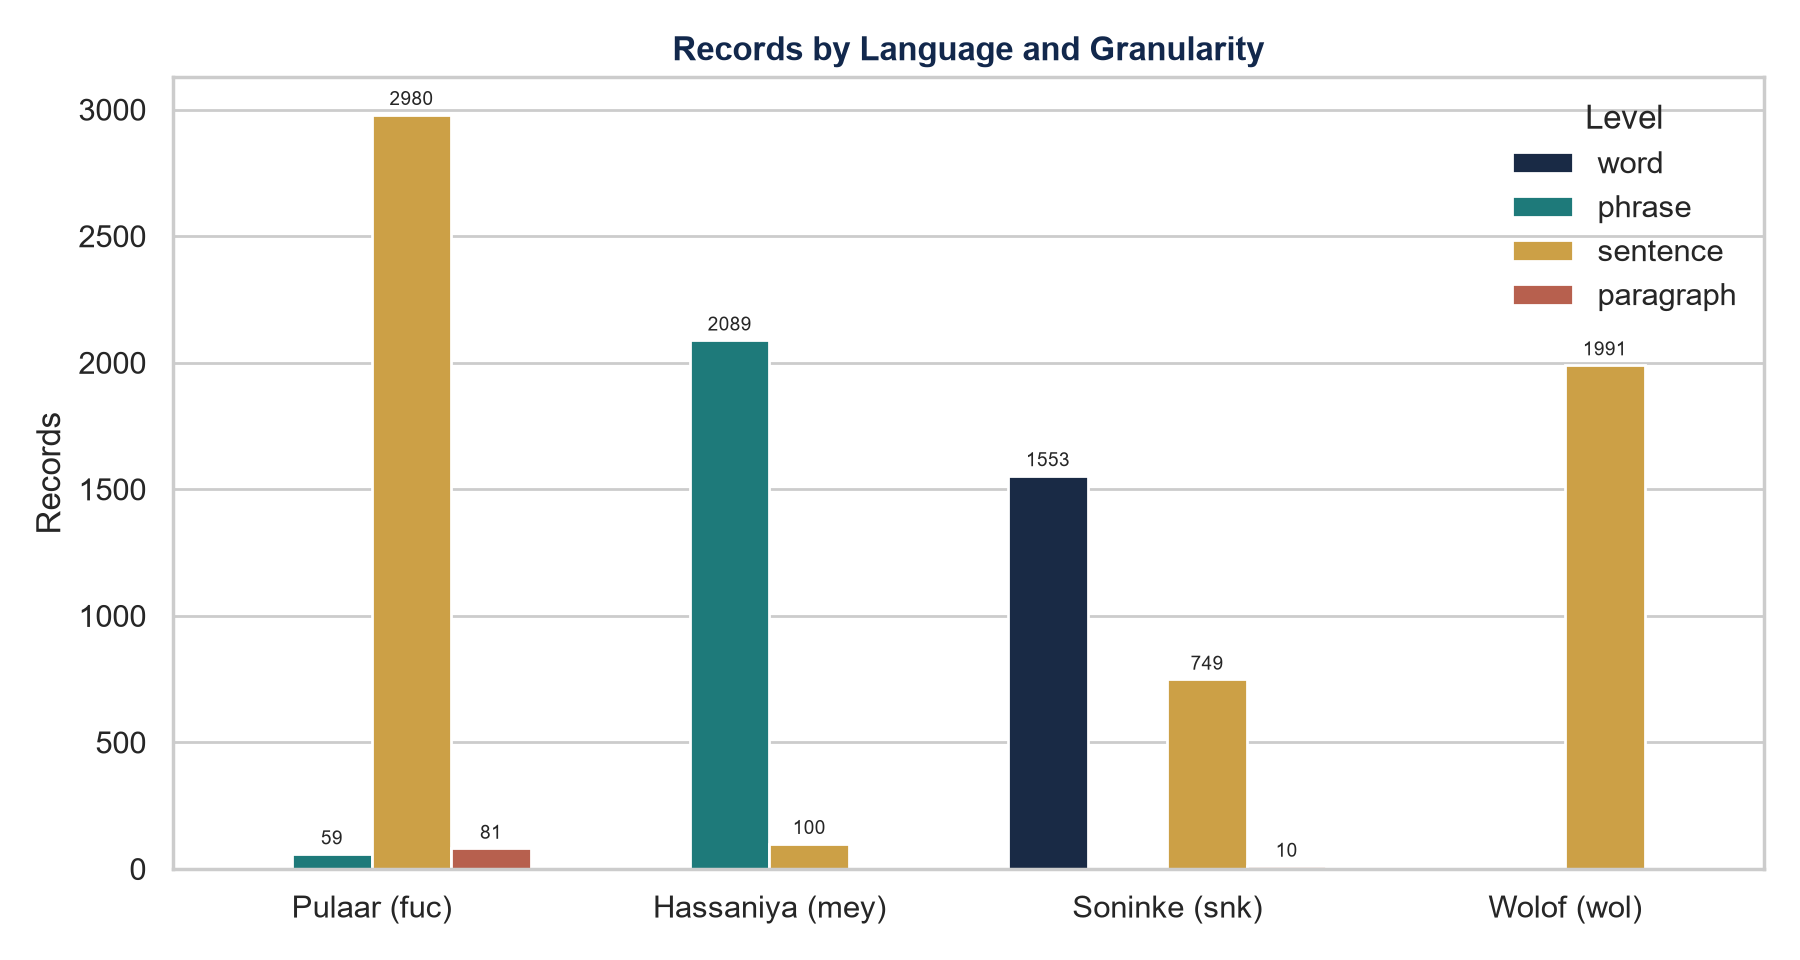

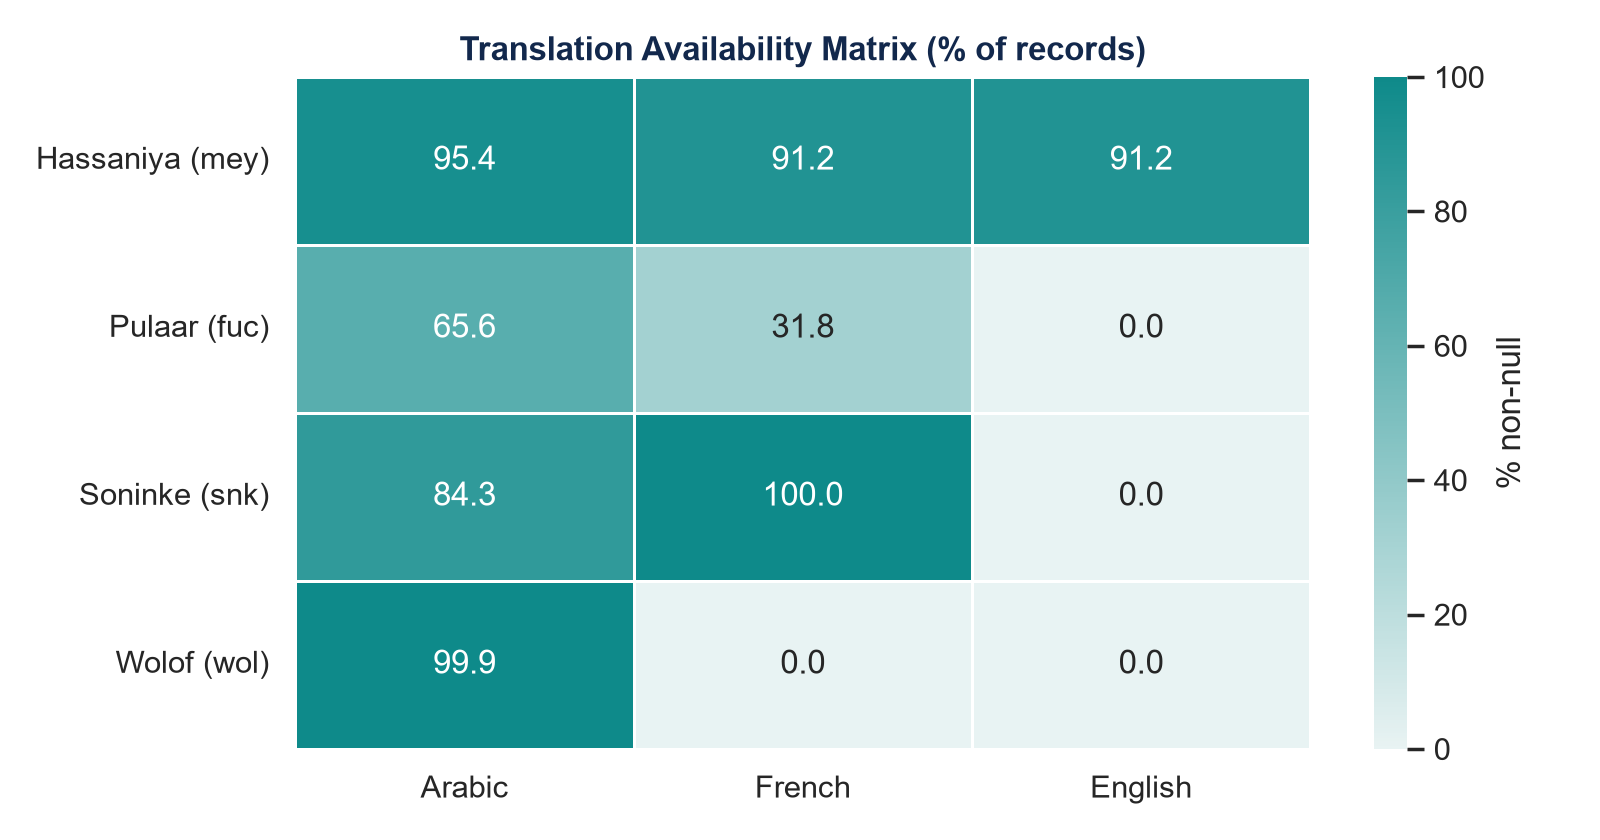

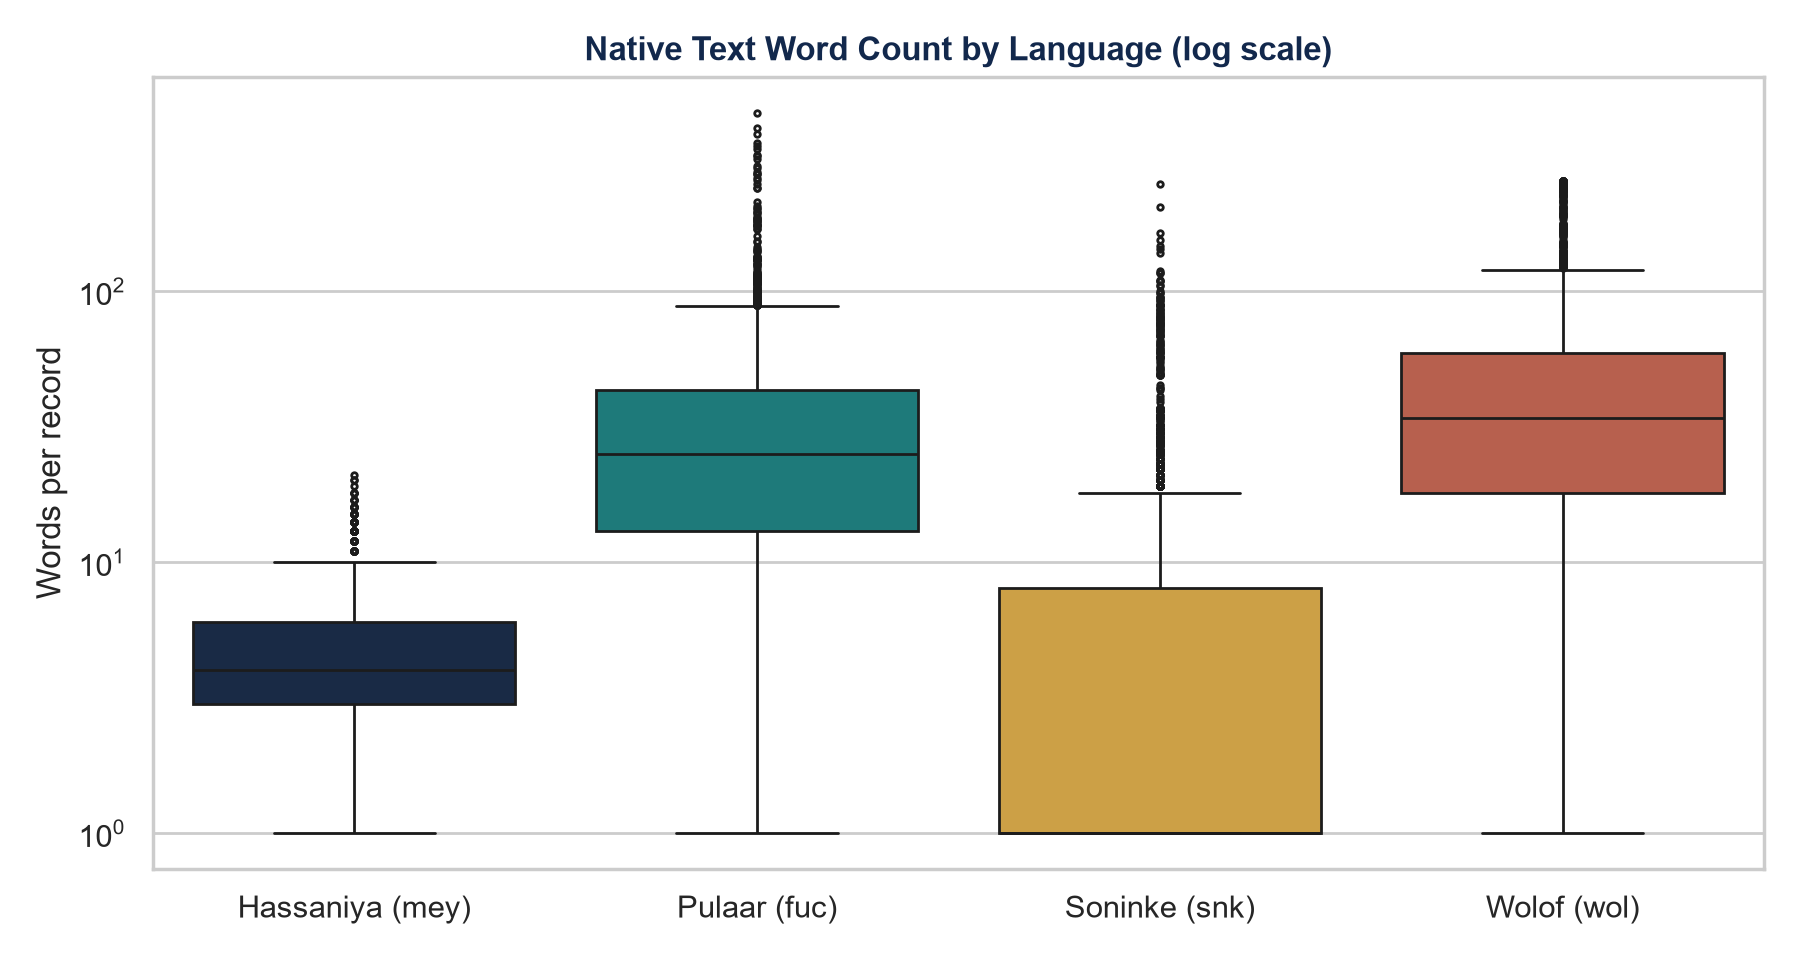

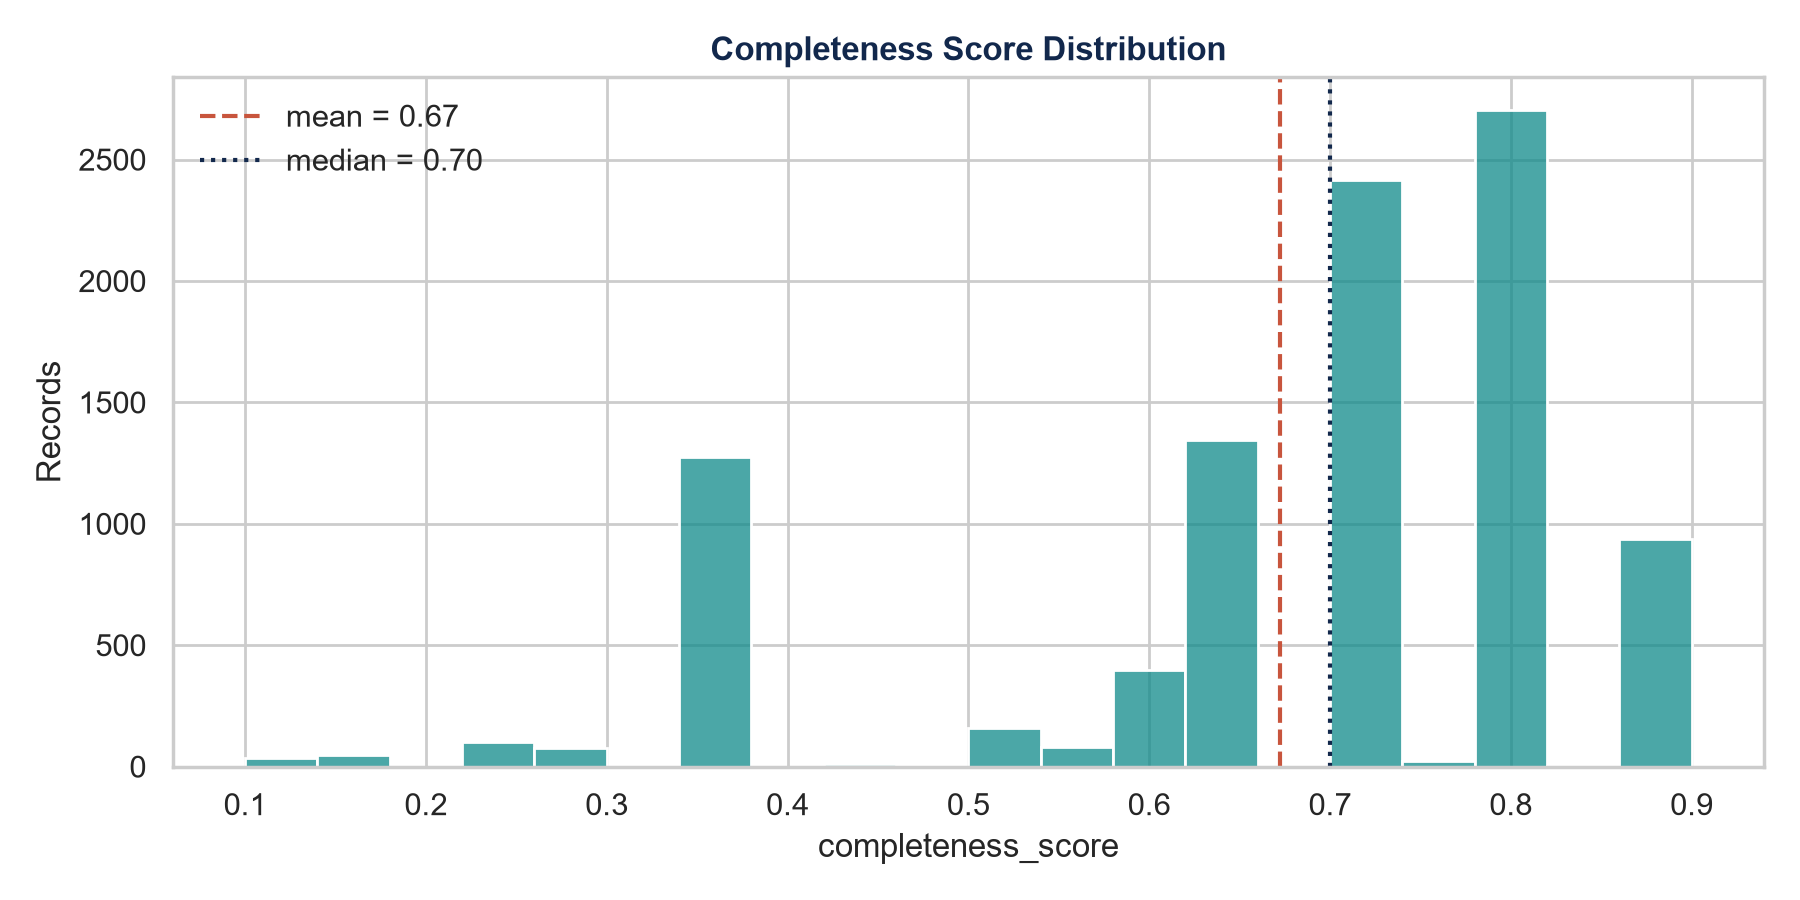

In [12]:
import tempfile
from IPython.display import Image as IPyImage
with tempfile.TemporaryDirectory() as td:
    charts = make_charts(clean, quality, Path(td))
    for k in ["dist", "avail", "words", "quality"]:
        if k in charts:
            display(IPyImage(filename=str(charts[k]), width=700))